# Proyecto final: tendencia de las emisiones anuales de CO₂ por país
**Curso:** Ciencia de Datos Profesional (Uniagraria) · **Actividad 4**
**Integrantes:** Julián Andrés (GitHub: salcedocamargo12) y Waira Ospina (GitHub: WairaCastro)

**Fuente:** Ritchie, H. y Roser, M. (2020). *CO₂ emissions*. Our World in Data. https://ourworldindata.org/co2-emissions
**Gráfico usado:** "Annual CO₂ emissions" (Our World in Data), datos del Global Carbon Budget (2026), descargados el 19 de noviembre de 2026. Unidad original: toneladas de CO₂ (solo territoriales, sin cambio de uso del suelo).

## Pregunta de investigación
El artículo muestra que las emisiones de CO₂ crecieron con la industrialización y que hay grandes diferencias entre países. Con la serie anual de cada país:

> **¿A qué ritmo han crecido las emisiones de CO₂ (mundo, Colombia y otros países) y qué tan bien describe ese crecimiento una regresión lineal?**

**Plan:** 1) Carga y revisión · 2) Limpieza · 3) Análisis exploratorio · 4) Regresión lineal paso a paso · 5) Interpretación · 6) Limitaciones.

## 0. Librerías

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LogNorm
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## 1. Carga de los datos
El archivo `annual-co2-emissions-per-country.csv` se descargó del sitio de Our World in Data. Debe estar en la misma carpeta que este notebook (en el repositorio de GitHub, por ejemplo dentro de `data/`).

In [2]:
RUTAS = ["annual-co2-emissions-per-country.csv", "data/annual-co2-emissions-per-country.csv"]
ruta = next((r for r in RUTAS if os.path.exists(r)), None)
assert ruta is not None, "No se encontró el CSV: póngalo junto al notebook o en la carpeta data/"

df_raw = pd.read_csv(ruta)
print("Filas, columnas:", df_raw.shape)
df_raw.head()

Filas, columnas: (30219, 4)


,Entity,Code,Year,Annual CO₂ emissions
0,Afghanistan,AFG,1949,"14,656.000"
1,Afghanistan,AFG,1950,"80,608.000"
2,Afghanistan,AFG,1951,"87,936.000"
3,Afghanistan,AFG,1952,"87,936.000"
4,Afghanistan,AFG,1953,"98,928.000"


### 1.1 Revisión inicial

In [3]:
print(df_raw.dtypes, "\n")
print("Valores faltantes por columna:")
print(df_raw.isna().sum(), "\n")
print("Entidades distintas:", df_raw["Entity"].nunique())
print("Rango de años:", df_raw["Year"].min(), "-", df_raw["Year"].max())
df_raw.describe()

Entity                      str
Code                        str
Year                      int64
Annual CO₂ emissions    float64
dtype: object 

Valores faltantes por columna:
Entity                     0
Code                    3330
Year                       0
Annual CO₂ emissions       0
dtype: int64 

Entidades distintas: 252
Rango de años: 1750 - 2025


,Year,Annual CO₂ emissions
count,"30,219.000","30,219.000"
mean,"1,948.382","416,443,812.706"
std,60.266,"1,980,807,613.945"
min,"1,750.000",0.000
25%,"1,913.000","340,752.000"
50%,"1,963.000","4,667,949.000"
75%,"1,996.000","51,619,332.000"
max,"2,025.000","38,995,104,000.000"


**Observaciones**
- Solo hay 4 columnas: entidad, código, año y emisiones (toneladas). No hay PIB ni población en este archivo, así que el modelo se basará en la **evolución en el tiempo** (tendencia).
- `Code` tiene faltantes: corresponden a **agregados** (por ejemplo "Asia (GCP)", "International shipping"), no a países.
- El archivo mezcla **países**, **regiones** (África, Asia, Europa...), **grupos por ingreso** y el total **Mundo**. Si se suman todos, se contaría varias veces la misma emisión. Por eso hay que separarlos.

## 2. Limpieza de datos
Cada paso explica **qué** se hizo y **por qué**, y se registra cuántas filas quedan.

In [4]:
log_limpieza = []
def registrar(paso, d):
    log_limpieza.append({"paso": paso, "filas": len(d)})

df = df_raw.copy()
registrar("0. Datos originales", df)

# Paso 1: nombres de columnas claros y unidades manejables
df = df.rename(columns={"Entity":"entidad","Code":"codigo","Year":"anio","Annual CO₂ emissions":"co2_t"})
df["co2_mt"] = df["co2_t"] / 1e6      # millones de toneladas (Mt)
df["co2_gt"] = df["co2_t"] / 1e9      # miles de millones de toneladas (Gt)
registrar("1. Renombrar columnas y crear Mt / Gt", df)

# Paso 2: duplicados país-año
print("Duplicados entidad-año:", df.duplicated(subset=["entidad","anio"]).sum())
df = df.drop_duplicates(subset=["entidad","anio"])
registrar("2. Sin duplicados entidad-año", df)

# Paso 3: valores negativos o nulos en la variable principal
print("Faltantes en co2_t:", df["co2_t"].isna().sum(), "| Negativos:", (df["co2_t"] < 0).sum())
df = df.dropna(subset=["co2_t"])
df = df[df["co2_t"] >= 0]
registrar("3. Sin faltantes ni negativos en CO₂", df)

# Paso 4: clasificar entidades. Un país tiene código ISO (3 letras) o es Kosovo (OWID_KOS).
es_agregado = df["codigo"].isna() | (df["codigo"].str.startswith("OWID_") & (df["codigo"] != "OWID_KOS"))
df["tipo"] = np.where(es_agregado, "agregado", "pais")
print(df.groupby("tipo")["entidad"].nunique())

paises    = df[df["tipo"] == "pais"].copy()
agregados = df[df["tipo"] == "agregado"].copy()
mundo     = agregados[agregados["entidad"] == "World"].set_index("anio").sort_index()
registrar("4. Solo países (agregados separados)", paises)
pd.DataFrame(log_limpieza)

Duplicados entidad-año: 0
Faltantes en co2_t: 0 | Negativos: 0
tipo
agregado     31
pais        221
Name: entidad, dtype: int64


,paso,filas
0,0. Datos originales,30219
1,1. Renombrar columnas y crear Mt / Gt,30219
2,2. Sin duplicados entidad-año,30219
3,3. Sin faltantes ni negativos en CO₂,30219
4,4. Solo países (agregados separados),24141


### 2.1 Ceros: ¿son errores o datos reales?

In [5]:
ceros = paises[paises["co2_t"] == 0]
print("Filas con 0 tCO₂ en países:", len(ceros), "| países afectados:", ceros["entidad"].nunique())
print("Años de esos ceros -> mínimo:", ceros["anio"].min(), "máximo:", ceros["anio"].max())
ceros.groupby("entidad")["anio"].agg(["min","max","count"]).sort_values("count", ascending=False).head(8)

Filas con 0 tCO₂ en países: 760 | países afectados: 25
Años de esos ceros -> mínimo: 1750 máximo: 2025


,min,max,count
entidad,,,
Taiwan,1750,1895,146
New Zealand,1750,1877,128
India,1750,1877,119
Norway,1750,1834,82
Australia,1750,1804,55
Paraguay,1890,1946,33
Christmas Island,1994,2025,32
Aruba,1926,1949,24


Los ceros son sobre todo de **años antiguos** (la gran mayoría antes de 1950, de países que aún no emitían de forma registrada). Se **conservan** porque son datos reales, y solo se excluyen cuando se usa logaritmo (que no admite 0).

### 2.2 Continuidad de las series (años faltantes dentro de cada país)

In [6]:
resumen = paises.groupby("entidad")["anio"].agg(primero="min", ultimo="max", n="count")
resumen["huecos"] = (resumen["ultimo"] - resumen["primero"] + 1) - resumen["n"]
print("Países con huecos dentro de su serie:", int((resumen["huecos"] > 0).sum()))
resumen.sort_values("huecos", ascending=False).head(8)

Países con huecos dentro de su serie: 47


,primero,ultimo,n,huecos
entidad,,,,
Ireland,1850,2025,115,61
Eritrea,1939,2025,38,49
Bolivia,1862,2025,137,27
Belgium,1802,2025,197,27
Azerbaijan,1830,2025,174,22
Estonia,1830,2025,174,22
Georgia,1830,2025,174,22
Armenia,1830,2025,174,22


Si hay huecos, no se rellenan (imputar emisiones inventaría datos). Cada regresión usa solo los años que sí existen.

### 2.3 Cambios bruscos año a año (posibles atípicos)

In [7]:
paises = paises.sort_values(["entidad","anio"])
paises["var_pct"] = paises.groupby("entidad")["co2_t"].pct_change() * 100
atip = paises[(paises["var_pct"].abs() > 100) & (paises["co2_mt"] > 5)]
print("Saltos de más de ±100% en un año con emisiones > 5 Mt:", len(atip))
atip[["entidad","anio","co2_mt","var_pct"]].sort_values("var_pct").head(10)

Saltos de más de ±100% en un año con emisiones > 5 Mt: 52


,entidad,anio,co2_mt,var_pct
6809,Curacao,1954,12.620,100.860
13470,Indonesia,1943,19.027,101.201
18889,New Caledonia,2025,5.153,101.976
20507,North Korea,2017,69.700,103.606
5765,China,1958,523.785,105.264
13833,Iraq,1939,12.157,105.449
15301,Laos,2015,9.412,107.058
14968,Kuwait,1960,7.390,108.799
18351,Mozambique,2014,8.409,109.632
18734,Netherlands,1946,31.101,112.089


Los cambios bruscos coinciden con hechos históricos: por ejemplo, las **quemas de pozos petroleros en Kuwait en 1991** (la fuente las incluye a propósito) o años de industrialización acelerada y guerra, como China en 1958. **No se eliminan**: son datos reales y quedan documentados. Además, el valor de **2025** puede ser preliminar (en Colombia baja cerca de 10% frente a 2024), por eso se usa 2024 como año de referencia.

In [8]:
print("Calidad final -> faltantes:", int(paises[["co2_t"]].isna().sum().sum()),
      "| países:", paises["entidad"].nunique(),
      "| años:", paises["anio"].min(), "-", paises["anio"].max())
pd.DataFrame(log_limpieza)

Calidad final -> faltantes: 0 | países: 221 | años: 1750 - 2025


,paso,filas
0,0. Datos originales,30219
1,1. Renombrar columnas y crear Mt / Gt,30219
2,2. Sin duplicados entidad-año,30219
3,3. Sin faltantes ni negativos en CO₂,30219
4,4. Solo países (agregados separados),24141


## 3. Visualización y análisis exploratorio

### 3.1 Emisiones mundiales desde 1750

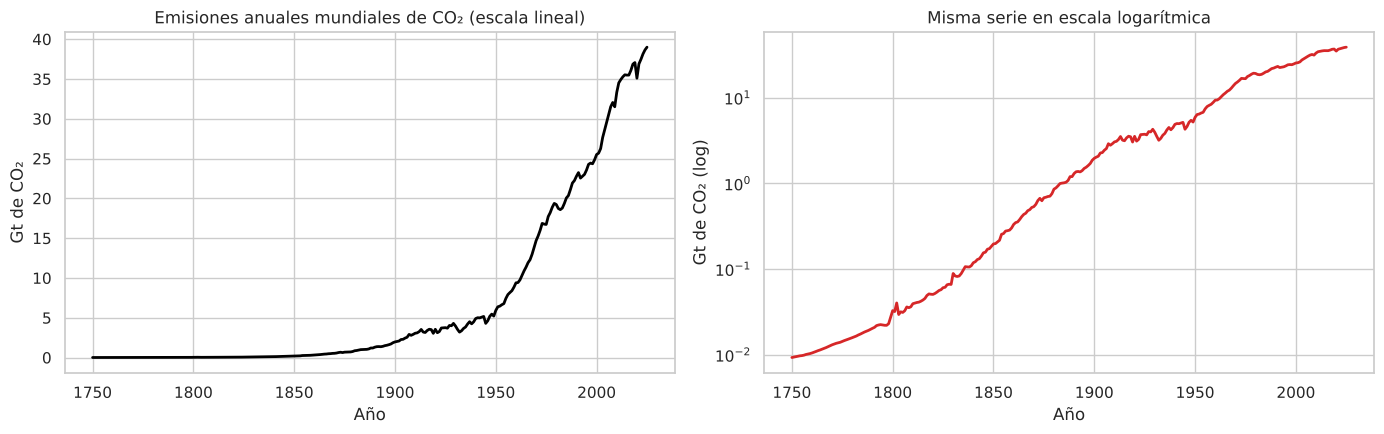

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(mundo.index, mundo["co2_gt"], color="black", lw=2)
axes[0].set_title("Emisiones anuales mundiales de CO₂ (escala lineal)")
axes[0].set_xlabel("Año"); axes[0].set_ylabel("Gt de CO₂")
axes[1].semilogy(mundo.index, mundo["co2_gt"], color="tab:red", lw=2)
axes[1].set_title("Misma serie en escala logarítmica")
axes[1].set_xlabel("Año"); axes[1].set_ylabel("Gt de CO₂ (log)")
plt.tight_layout(); plt.show()

**Lectura:** hasta 1850 las emisiones son casi nulas; luego crecen con la Revolución Industrial y se aceleran después de 1950. En escala logarítmica se ve mejor el ritmo de cambio: un crecimiento muy rápido al inicio que luego se va frenando (la curva se aplana).

### 3.2 Emisiones por región

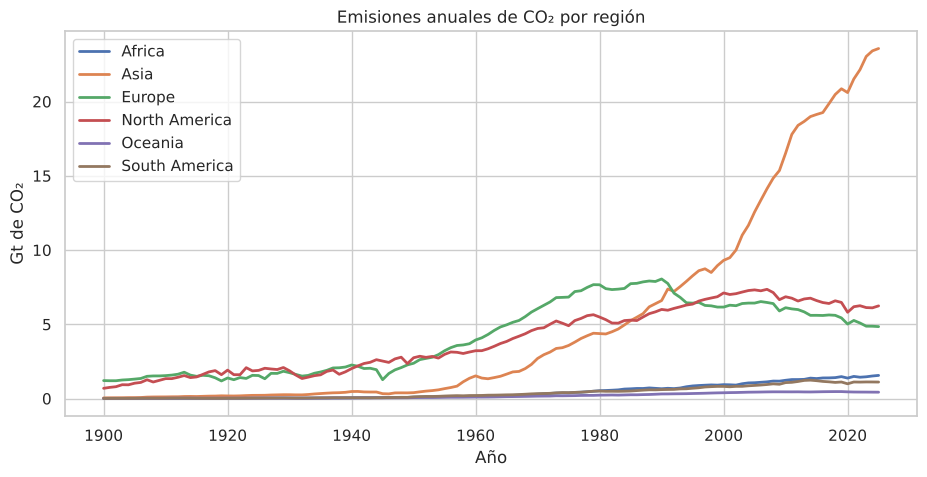

In [10]:
regiones = ["Africa","Asia","Europe","North America","South America","Oceania"]
reg = agregados[agregados["entidad"].isin(regiones) & (agregados["anio"] >= 1900)]
fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=reg, x="anio", y="co2_gt", hue="entidad", ax=ax, lw=2)
ax.set_title("Emisiones anuales de CO₂ por región"); ax.set_xlabel("Año"); ax.set_ylabel("Gt de CO₂")
ax.legend(title="")
plt.show()

**Lectura:** Europa y Norteamérica lideraron a mitad del siglo XX (en 1950 emitían alrededor de 2,4 y 2,8 Gt, frente a 0,4 Gt de Asia). Asia supera a Norteamérica en 1986 y a Europa en 1992, y hoy emite cerca de 23 Gt al año, mucho más que cualquier otra región.

### 3.3 Mayores emisores en el año de referencia

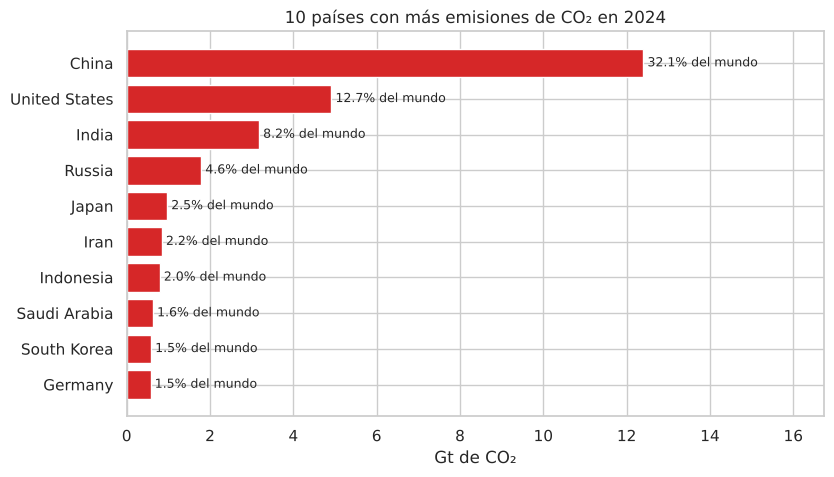

In [11]:
ANIO_REF = 2024   # último año con datos completos (2025 puede ser una estimación preliminar)
ref = paises[paises["anio"] == ANIO_REF].nlargest(10, "co2_mt").sort_values("co2_mt")
total_mundo_ref = mundo.loc[ANIO_REF, "co2_mt"]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(ref["entidad"], ref["co2_mt"]/1000, color="tab:red")
for y, v in enumerate(ref["co2_mt"]):
    ax.text(v/1000 + 0.1, y, f"{v/total_mundo_ref*100:.1f}% del mundo", va="center", fontsize=9)
ax.set_title(f"10 países con más emisiones de CO₂ en {ANIO_REF}")
ax.set_xlabel("Gt de CO₂"); ax.set_xlim(0, ref["co2_mt"].max()/1000*1.35)
plt.show()
print(f"Los 10 mayores emisores suman {ref['co2_mt'].sum()/total_mundo_ref*100:.1f}% de las emisiones mundiales de {ANIO_REF}")

### 3.4 Responsabilidad histórica: emisiones acumuladas desde el inicio de la serie

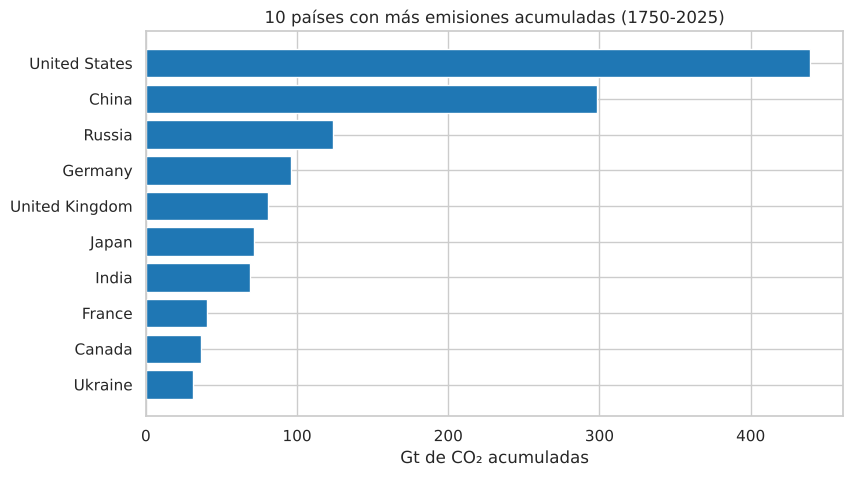

In [12]:
acum = paises.groupby("entidad")["co2_gt"].sum().nlargest(10).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(acum.index, acum.values, color="tab:blue")
ax.set_title("10 países con más emisiones acumuladas (1750-2025)")
ax.set_xlabel("Gt de CO₂ acumuladas")
plt.show()

**Lectura:** el orden cambia respecto al año reciente. Estados Unidos lidera lo acumulado (unas 439 Gt), seguido de China (unas 299 Gt), Rusia y Alemania; India, hoy tercer emisor, aparece séptima. Esto conecta con la discusión del artículo sobre **responsabilidades compartidas** y desigualdad entre países.

### 3.5 Mapa de calor por década (12 mayores emisores actuales)

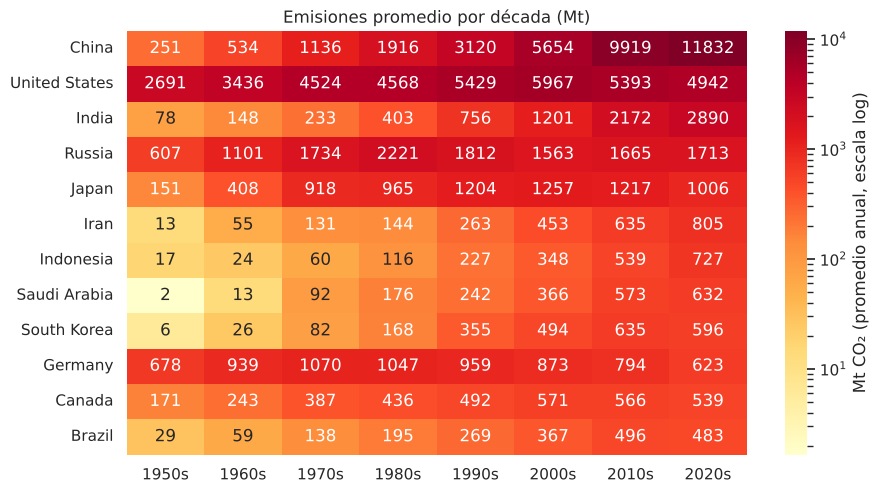

In [13]:
top12 = paises[paises["anio"] == ANIO_REF].nlargest(12, "co2_mt")["entidad"].tolist()
p = paises[paises["entidad"].isin(top12) & (paises["anio"] >= 1950)].copy()
p["decada"] = (p["anio"] // 10 * 10).astype(str) + "s"
tabla = p.pivot_table(index="entidad", columns="decada", values="co2_mt", aggfunc="mean").loc[top12]
plt.figure(figsize=(10, 5.5))
sns.heatmap(tabla, annot=True, fmt=".0f", cmap="YlOrRd", norm=LogNorm(), cbar_kws={"label":"Mt CO₂ (promedio anual, escala log)"})
plt.title("Emisiones promedio por década (Mt)"); plt.ylabel(""); plt.xlabel("")
plt.show()

### 3.6 Colombia y países de la región

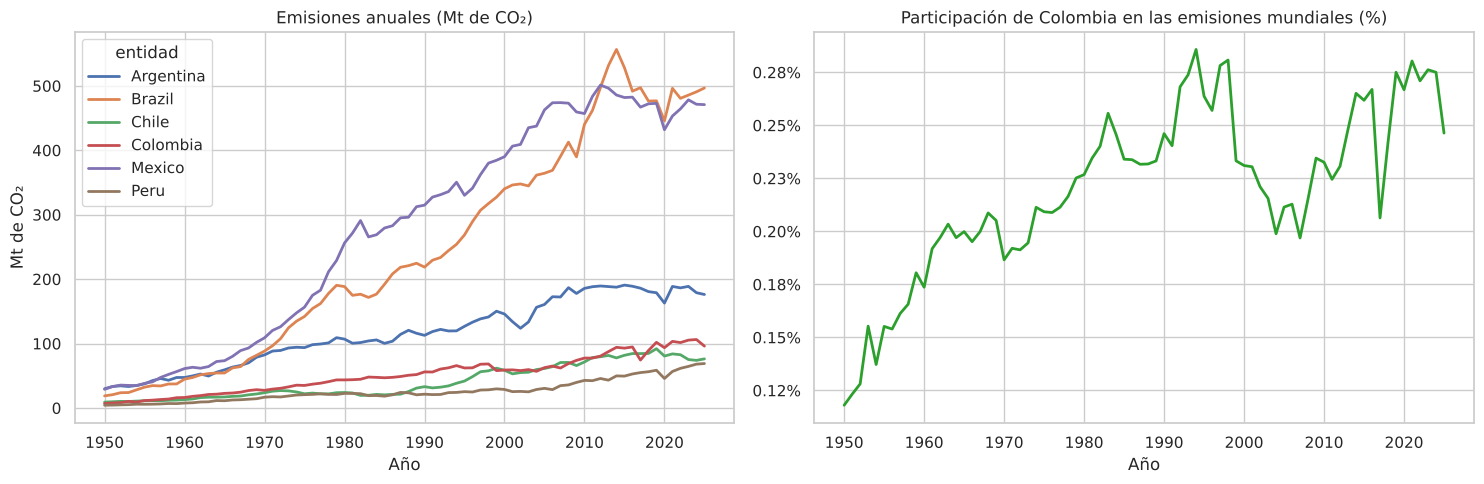

In [14]:
vecinos = ["Colombia","Brazil","Mexico","Argentina","Chile","Peru"]
sub = paises[paises["entidad"].isin(vecinos) & (paises["anio"] >= 1950)]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.lineplot(data=sub, x="anio", y="co2_mt", hue="entidad", ax=axes[0], lw=2)
axes[0].set_title("Emisiones anuales (Mt de CO₂)"); axes[0].set_xlabel("Año"); axes[0].set_ylabel("Mt de CO₂")
col = paises[(paises["entidad"] == "Colombia") & (paises["anio"] >= 1950)].set_index("anio")
share = col["co2_mt"] / mundo.loc[col.index, "co2_mt"] * 100
axes[1].plot(share.index, share.values, color="tab:green", lw=2)
axes[1].set_title("Participación de Colombia en las emisiones mundiales (%)")
axes[1].set_xlabel("Año"); axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=2))
plt.tight_layout(); plt.show()

### 3.7 Desigualdad entre grupos de ingreso

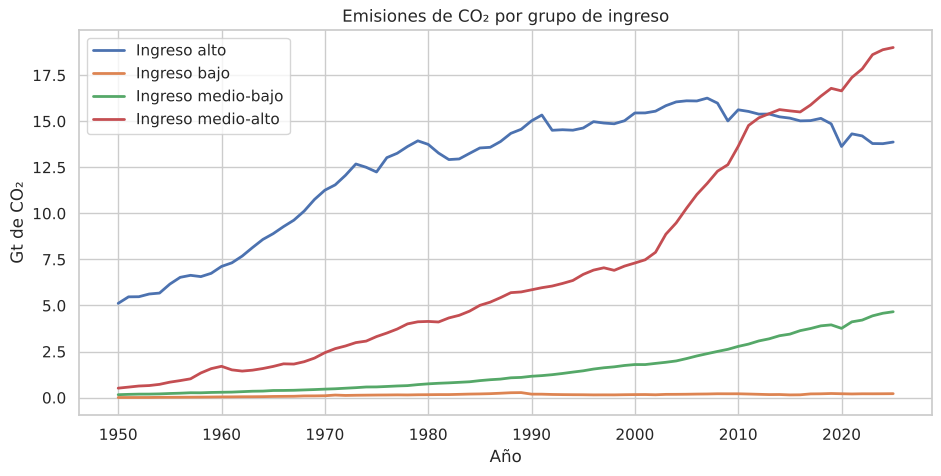

In [15]:
ingresos = {"High-income countries":"Ingreso alto","Upper-middle-income countries":"Ingreso medio-alto",
            "Lower-middle-income countries":"Ingreso medio-bajo","Low-income countries":"Ingreso bajo"}
g = agregados[agregados["entidad"].isin(ingresos) & (agregados["anio"] >= 1950)].copy()
g["grupo"] = g["entidad"].map(ingresos)
fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=g, x="anio", y="co2_gt", hue="grupo", ax=ax, lw=2)
ax.set_title("Emisiones de CO₂ por grupo de ingreso"); ax.set_xlabel("Año"); ax.set_ylabel("Gt de CO₂"); ax.legend(title="")
plt.show()

**Lectura:** los países de ingreso alto dominaron hasta 2012; en 2013 los de ingreso medio-alto (donde está China) los superan. Los de ingreso bajo emiten apenas ~0,2 Gt al año, reflejo de la desigualdad que describe el artículo.

### 3.8 Distribución de las emisiones entre países

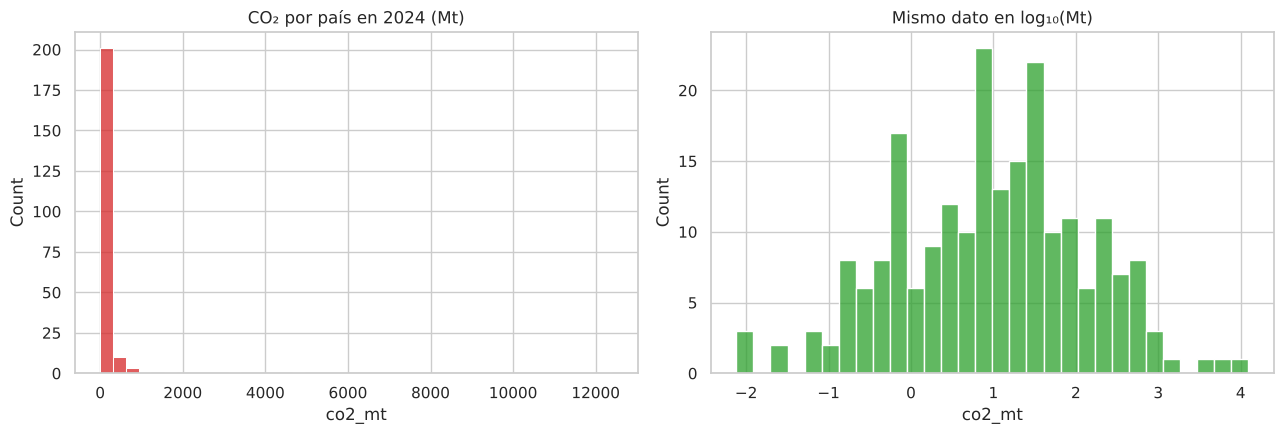

In [16]:
d = paises[(paises["anio"] == ANIO_REF) & (paises["co2_mt"] > 0)]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(d["co2_mt"], bins=40, ax=axes[0], color="tab:red"); axes[0].set_title(f"CO₂ por país en {ANIO_REF} (Mt)")
sns.histplot(np.log10(d["co2_mt"]), bins=30, ax=axes[1], color="tab:green"); axes[1].set_title("Mismo dato en log₁₀(Mt)")
plt.tight_layout(); plt.show()
print("Mediana:", round(d["co2_mt"].median(), 1), "Mt | Media:", round(d["co2_mt"].mean(), 1), "Mt")

**Lectura:** unos pocos países emiten muchísimo y la mayoría emite poco (distribución muy sesgada: la media supera con creces a la mediana). Por eso, al comparar países conviene usar escala logarítmica o porcentajes.

## 4. Modelo de regresión lineal (paso a paso)

**Idea:** describir cómo cambian las emisiones con el tiempo mediante una recta.

$$\hat{y}_t = \beta_0 + \beta_1\, t$$

donde $y$ = emisiones (Gt de CO₂) y $t$ = año. Aquí $\beta_1$ es la **pendiente**: cuánto aumentan las emisiones, en promedio, **cada año**.

**Fórmulas de mínimos cuadrados (OLS):**

$$\beta_1 = \frac{S_{xy}}{S_{xx}} = \frac{\sum (x_i-\bar{x})(y_i-\bar{y})}{\sum (x_i-\bar{x})^2} \qquad \beta_0 = \bar{y} - \beta_1\bar{x}$$

**Métricas:**

$$R^2 = 1 - \frac{SSE}{SST},\quad SSE=\sum (y_i-\hat{y}_i)^2,\quad SST=\sum (y_i-\bar{y})^2 \qquad RMSE=\sqrt{SSE/n}$$

**Validación:** se entrena con datos de **1950 a 2015** y se prueba con **2016 a 2025**: así se evalúa si la recta predice años que no vio.

### 4.1 Datos del modelo (mundo) y partición

In [17]:
datos = mundo.loc[1950:2025, ["co2_gt"]].reset_index()
train = datos[datos["anio"] <= 2015]
test  = datos[datos["anio"] >  2015]
print("Entrenamiento:", len(train), "años (", train["anio"].min(), "-", train["anio"].max(), ")")
print("Prueba:       ", len(test),  "años (", test["anio"].min(),  "-", test["anio"].max(),  ")")
x, y = train["anio"].to_numpy(float), train["co2_gt"].to_numpy(float)

Entrenamiento: 66 años ( 1950 - 2015 )
Prueba:        10 años ( 2016 - 2025 )


### 4.2 Cálculo manual de la recta (operación por operación)

In [18]:
n     = len(x)                                   # Operación 1: número de observaciones
x_bar = x.mean()                                 # Operación 2: media de x (año)
y_bar = y.mean()                                 # Operación 3: media de y (Gt)
Sxy   = np.sum((x - x_bar) * (y - y_bar))        # Operación 4: suma de productos cruzados
Sxx   = np.sum((x - x_bar) ** 2)                 # Operación 5: suma de cuadrados de x
b1    = Sxy / Sxx                                # Operación 6: pendiente
b0    = y_bar - b1 * x_bar                       # Operación 7: intercepto
y_hat = b0 + b1 * x                              # Operación 8: valores ajustados
SSE   = np.sum((y - y_hat) ** 2)                 # Operación 9: suma de cuadrados del error
SST   = np.sum((y - y_bar) ** 2)                 # Operación 10: suma total de cuadrados
R2    = 1 - SSE / SST                            # Operación 11: coeficiente de determinación
RMSE  = np.sqrt(SSE / n)                         # Operación 12: error cuadrático medio (raíz)

pasos = pd.DataFrame({
    "Operación": ["n","x̄","ȳ","Sxy","Sxx","β₁ = Sxy/Sxx","β₀ = ȳ − β₁x̄","SSE","SST","R² = 1 − SSE/SST","RMSE"],
    "Valor":     [n, x_bar, y_bar, Sxy, Sxx, b1, b0, SSE, SST, R2, RMSE]})
pasos

,Operación,Valor
0,n,66.000
1,x̄,"1,982.500"
2,ȳ,19.542
3,Sxy,"10,670.848"
4,Sxx,"23,952.500"
5,β₁ = Sxy/Sxx,0.446
6,β₀ = ȳ − β₁x̄,-863.663
7,SSE,80.271
8,SST,"4,834.138"
9,R² = 1 − SSE/SST,0.983


**Interpretación de β₁:** cada año, las emisiones mundiales aumentaron en promedio ese número de Gt de CO₂ durante 1950-2015. El intercepto β₀ no tiene lectura física directa (sería el valor en el año 0), solo ancla la recta.

### 4.3 Verificación con librerías (scikit-learn y SciPy)

In [19]:
lr = LinearRegression().fit(train[["anio"]], train["co2_gt"])
res = stats.linregress(x, y)
comp = pd.DataFrame({"Manual":[b1, b0, R2], "scikit-learn":[lr.coef_[0], lr.intercept_, lr.score(train[["anio"]], train["co2_gt"])],
                     "SciPy":[res.slope, res.intercept, res.rvalue**2]}, index=["Pendiente β₁","Intercepto β₀","R²"])
display(comp)

t_crit = stats.t.ppf(0.975, df=n-2)
print(f"Error estándar de β₁: {res.stderr:.5f}")
print(f"IC 95% para β₁: [{res.slope - t_crit*res.stderr:.4f}, {res.slope + t_crit*res.stderr:.4f}] Gt/año")
print(f"Valor p de la pendiente: {res.pvalue:.2e}  (H0: β₁ = 0)")

,Manual,scikit-learn,SciPy
Pendiente β₁,0.446,0.446,0.446
Intercepto β₀,-863.663,-863.663,-863.663
R²,0.983,0.983,0.983


Los tres métodos dan el mismo resultado, lo que valida el cálculo manual. Un valor p muy pequeño indica que la pendiente es significativamente distinta de cero (hay tendencia creciente).

### 4.4 Evaluación en datos de prueba (2016-2025)

In [20]:
pred_tr = lr.predict(train[["anio"]]); pred_te = lr.predict(test[["anio"]])
metricas = pd.DataFrame({
    "R²":   [r2_score(train["co2_gt"], pred_tr), r2_score(test["co2_gt"], pred_te)],
    "RMSE (Gt)": [np.sqrt(mean_squared_error(train["co2_gt"], pred_tr)), np.sqrt(mean_squared_error(test["co2_gt"], pred_te))],
    "MAE (Gt)":  [mean_absolute_error(train["co2_gt"], pred_tr), mean_absolute_error(test["co2_gt"], pred_te)],
    "Error % medio": [np.mean(np.abs(train["co2_gt"]-pred_tr)/train["co2_gt"])*100, np.mean(np.abs(test["co2_gt"]-pred_te)/test["co2_gt"])*100],
}, index=["Entrenamiento (1950-2015)","Prueba (2016-2025)"])
metricas

,R²,RMSE (Gt),MAE (Gt),Error % medio
Entrenamiento (1950-2015),0.983,1.103,0.885,4.570
Prueba (2016-2025),0.420,0.932,0.832,2.266


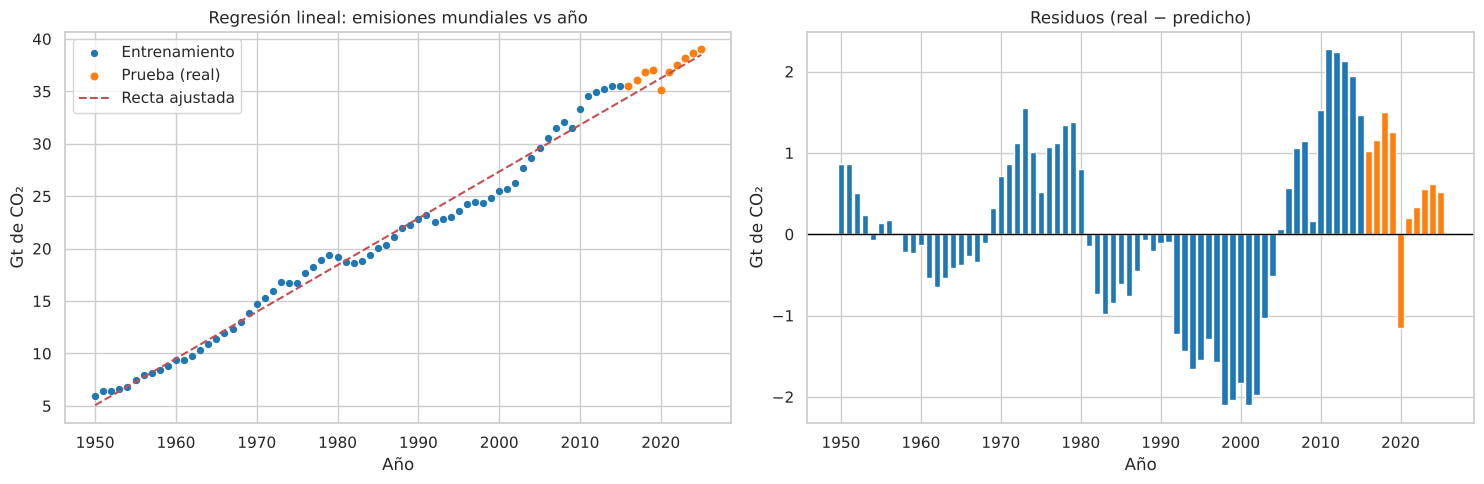

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].scatter(train["anio"], train["co2_gt"], s=18, label="Entrenamiento", color="tab:blue")
axes[0].scatter(test["anio"],  test["co2_gt"],  s=22, label="Prueba (real)", color="tab:orange")
anios = np.arange(1950, 2026)
axes[0].plot(anios, lr.predict(pd.DataFrame({"anio": anios})), "r--", label="Recta ajustada")
axes[0].set_title("Regresión lineal: emisiones mundiales vs año"); axes[0].set_xlabel("Año"); axes[0].set_ylabel("Gt de CO₂"); axes[0].legend()

todo = datos.assign(pred=lr.predict(datos[["anio"]]))
axes[1].bar(todo["anio"], todo["co2_gt"] - todo["pred"], color=np.where(todo["anio"] > 2015, "tab:orange", "tab:blue"))
axes[1].axhline(0, color="black", lw=1)
axes[1].set_title("Residuos (real − predicho)"); axes[1].set_xlabel("Año"); axes[1].set_ylabel("Gt de CO₂")
plt.tight_layout(); plt.show()

**Lectura del diagnóstico:** si los residuos formaran una curva (positivos, luego negativos, luego positivos) significaría que la relación **no es perfectamente lineal**. En 2016-2025 casi todos los residuos son **positivos**: la recta entrenada hasta 2015 queda por debajo de lo real (subestima) salvo en 2020, año de la pandemia, cuando las emisiones cayeron. El R² de prueba es bajo (0,42) porque en esos 10 años la serie varía poco alrededor de su promedio, aunque el error porcentual medio es pequeño (~2,3%).

### 4.5 Modelo log-lineal: tasa de crecimiento porcentual

Si se aplica logaritmo natural a las emisiones, la pendiente se interpreta como **tasa de crecimiento porcentual anual**:

$$\ln(y_t) = \alpha_0 + \alpha_1 t \quad\Rightarrow\quad \text{crecimiento anual} \approx (e^{\alpha_1}-1)\times 100\,\%$$

In [22]:
def ajustar(serie, anio_ini, anio_fin):
    """Ajusta y = b0 + b1*t y ln(y) = a0 + a1*t para una serie indexada por año. Devuelve un diccionario de resultados."""
    s = serie.loc[anio_ini:anio_fin].dropna()
    s = s[s > 0]
    r_lin = stats.linregress(s.index.astype(float), s.values)
    r_log = stats.linregress(s.index.astype(float), np.log(s.values))
    return {"n": len(s), "pendiente_Mt_anio": r_lin.slope, "R2_lineal": r_lin.rvalue**2,
            "crec_pct_anual": (np.exp(r_log.slope) - 1) * 100, "R2_log": r_log.rvalue**2}

periodos = [(1950, 1979), (1980, 1999), (2000, 2015), (2016, 2025)]
filas = []
for a, b in periodos:
    r = ajustar(mundo["co2_mt"], a, b); r["periodo"] = f"{a}-{b}"; filas.append(r)
tabla_mundo = pd.DataFrame(filas).set_index("periodo")
tabla_mundo.rename(columns={"pendiente_Mt_anio":"Pendiente (Mt/año)","R2_lineal":"R² lineal","crec_pct_anual":"Crec. % anual","R2_log":"R² log"})

,n,Pendiente (Mt/año),R² lineal,Crec. % anual,R² log
periodo,,,,,
1950-1979,30,482.370,0.982,4.323,0.994
1980-1999,20,348.109,0.945,1.629,0.937
2000-2015,16,743.225,0.972,2.460,0.962
2016-2025,10,357.473,0.704,0.964,0.696


**Lectura:** la tasa de crecimiento porcentual **no es constante**: pasa de 4,3% anual (1950-1979) a 1,6% (1980-1999), repunta a 2,5% (2000-2015, auge de China) y baja a ~1,0% (2016-2025). Esto explica por qué una sola recta para todo el periodo no describe perfecto los años recientes.

### 4.6 Colombia

,n,Pendiente (Mt/año),R² lineal,Crec. % anual,R² log
periodo,,,,,
1950-1979,30,1.215,0.988,6.170,0.973
1980-1999,20,1.305,0.865,2.430,0.882
2000-2015,16,2.543,0.899,3.564,0.915
2016-2024,9,2.751,0.549,3.003,0.515


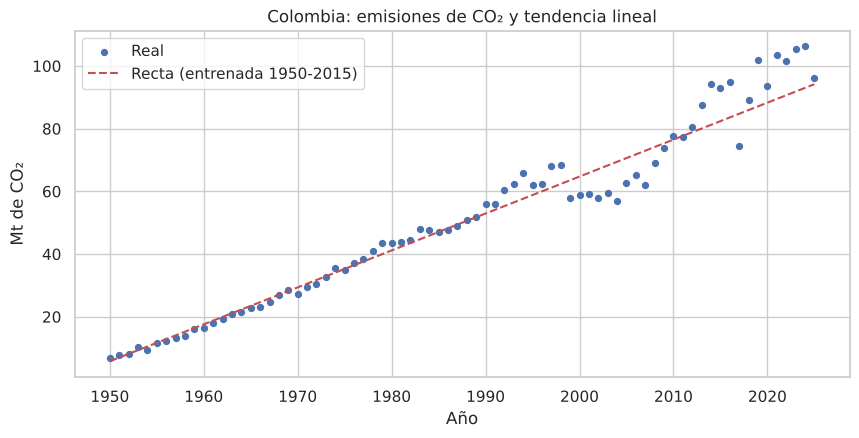

In [23]:
col_s = paises[paises["entidad"] == "Colombia"].set_index("anio")["co2_mt"]
filas = []
for a, b in [(1950, 1979), (1980, 1999), (2000, 2015), (2016, 2024)]:
    r = ajustar(col_s, a, b); r["periodo"] = f"{a}-{b}"; filas.append(r)
tabla_col = pd.DataFrame(filas).set_index("periodo")
display(tabla_col.rename(columns={"pendiente_Mt_anio":"Pendiente (Mt/año)","R2_lineal":"R² lineal","crec_pct_anual":"Crec. % anual","R2_log":"R² log"}))

# Mismo esquema train/test que el mundo
c = col_s.loc[1950:2025].reset_index(); c.columns = ["anio","co2_mt"]
c_tr, c_te = c[c["anio"] <= 2015], c[c["anio"] > 2015]
m = LinearRegression().fit(c_tr[["anio"]], c_tr["co2_mt"])
print(f"Colombia 1950-2015: pendiente = {m.coef_[0]:.3f} Mt/año | R² entrenamiento = {m.score(c_tr[['anio']], c_tr['co2_mt']):.3f}")
print(f"Colombia 2016-2025: RMSE prueba = {np.sqrt(mean_squared_error(c_te['co2_mt'], m.predict(c_te[['anio']]))):.2f} Mt | R² prueba = {r2_score(c_te['co2_mt'], m.predict(c_te[['anio']])):.3f}")

plt.figure(figsize=(10, 4.5))
plt.scatter(c["anio"], c["co2_mt"], s=18, label="Real")
a2 = np.arange(1950, 2026)
plt.plot(a2, m.predict(pd.DataFrame({"anio": a2})), "r--", label="Recta (entrenada 1950-2015)")
plt.title("Colombia: emisiones de CO₂ y tendencia lineal"); plt.xlabel("Año"); plt.ylabel("Mt de CO₂"); plt.legend()
plt.show()

### 4.7 Muchas regresiones: tendencia reciente (2000-2024) de todos los países

In [24]:
filas = []
for pais, g in paises[(paises["anio"].between(2000, 2024))].groupby("entidad"):
    s = g.set_index("anio")["co2_mt"]
    if len(s) < 20 or (s <= 0).any() or s.loc[2000] < 1:    # series completas y países no minúsculos
        continue
    r = ajustar(s, 2000, 2024); r["pais"] = pais; r["Mt_2024"] = s.loc[2024]; filas.append(r)
tend = pd.DataFrame(filas).set_index("pais")
print("Países analizados:", len(tend))
display(tend.sort_values("crec_pct_anual", ascending=False)[["crec_pct_anual","pendiente_Mt_anio","R2_log","Mt_2024"]].head(8))
display(tend.sort_values("crec_pct_anual")[["crec_pct_anual","pendiente_Mt_anio","R2_log","Mt_2024"]].head(8))

Países analizados: 158


,crec_pct_anual,pendiente_Mt_anio,R2_log,Mt_2024
pais,,,,
Cambodia,12.751,1.035,0.975,27.324
Afghanistan,10.367,0.420,0.729,10.741
Mozambique,9.367,0.402,0.925,8.601
Mali,9.349,0.289,0.982,7.350
Nepal,9.332,0.640,0.926,15.798
Tanzania,8.893,0.765,0.970,18.808
Zambia,8.801,0.413,0.973,10.602
Mongolia,8.373,1.519,0.976,41.763


,crec_pct_anual,pendiente_Mt_anio,R2_log,Mt_2024
pais,,,,
Aruba,-6.253,-0.101,0.760,0.881
Curacao,-5.412,-0.167,0.538,1.530
Syria,-3.624,-1.505,0.612,29.427
Denmark,-3.499,-1.471,0.935,27.027
Greece,-3.385,-2.788,0.880,53.713
Ukraine,-3.062,-7.136,0.712,134.085
Finland,-3.062,-1.523,0.846,29.903
United Kingdom,-2.907,-12.996,0.935,317.547


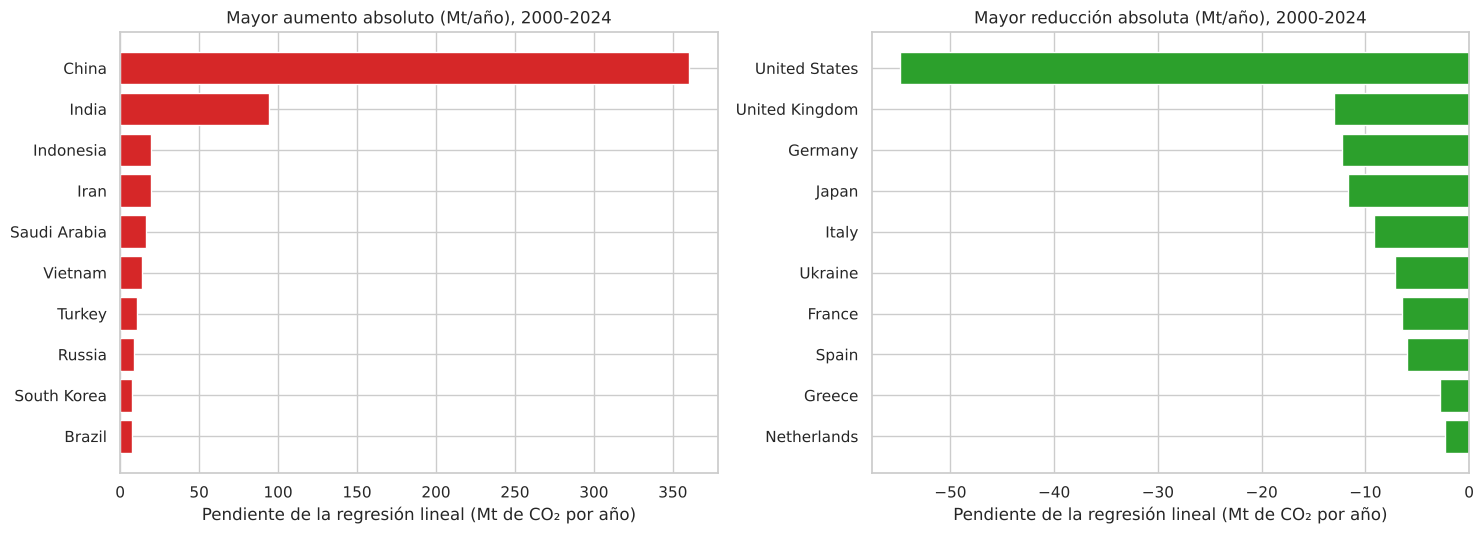

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
mas = tend.nlargest(10, "pendiente_Mt_anio").sort_values("pendiente_Mt_anio")
axes[0].barh(mas.index, mas["pendiente_Mt_anio"], color="tab:red"); axes[0].set_title("Mayor aumento absoluto (Mt/año), 2000-2024")
menos = tend.nsmallest(10, "pendiente_Mt_anio").sort_values("pendiente_Mt_anio", ascending=False)
axes[1].barh(menos.index, menos["pendiente_Mt_anio"], color="tab:green"); axes[1].set_title("Mayor reducción absoluta (Mt/año), 2000-2024")
for ax in axes: ax.set_xlabel("Pendiente de la regresión lineal (Mt de CO₂ por año)")
plt.tight_layout(); plt.show()
print("Colombia en este ranking -> crec. anual: %.2f %% | pendiente: %.2f Mt/año" % (tend.loc["Colombia","crec_pct_anual"], tend.loc["Colombia","pendiente_Mt_anio"]))

## 5. Interpretación de resultados

**1. Tendencia mundial (modelo lineal, 1950-2015).**
- Pendiente β₁ ≈ **0,446 Gt de CO₂ por año** (IC 95%: 0,431 a 0,460). Cada año las emisiones mundiales aumentaron en promedio unos 446 millones de toneladas.
- R² = **0,983**: el tiempo por sí solo explica ~98% de la variación en 1950-2015, y la pendiente es significativa (valor p ≈ 1e-58).
- El modelo manual coincide con scikit-learn y SciPy.

**2. Capacidad de predicción (2016-2025).**
- RMSE de prueba ≈ 0,93 Gt y error porcentual medio ≈ 2,3%: la recta predice razonablemente bien el nivel de emisiones.
- Pero R² de prueba = 0,42 y los residuos son casi todos positivos: la recta **subestima** los años recientes porque el crecimiento cambió de ritmo.

**3. Cambio de ritmo (modelo log-lineal).**
- Crecimiento anual: 4,3% (1950-79), 1,6% (1980-99), 2,5% (2000-15) y ~1,0% (2016-25).
- Las emisiones siguen subiendo en términos absolutos (alrededor de 39 Gt en 2025), pero cada vez más despacio. Esto es coherente con el artículo, que muestra una desaceleración del crecimiento en las últimas décadas, pero no una caída sostenida.

**4. Colombia.**
- Emitió ~106 Mt en 2024 (≈0,28% del total mundial; era ≈0,12% en 1950 y ≈0,23% en 2000), frente a ~491 Mt de Brasil y ~471 Mt de México.
- Entre 2000 y 2024 creció ~2,9% anual (≈2,2 Mt por año, R² = 0,90).
- La recta entrenada hasta 2015 (1,18 Mt/año, R² = 0,96) **no predice bien** 2016-2025 (R² de prueba = −0,41, peor que predecir el promedio): desde 2016 las emisiones se mueven entre ~90 y ~106 Mt, con una meseta, y no siguen la recta.

**5. Comparación entre países (2000-2024).**
- Mayor aumento absoluto: China (≈ +360 Mt por año) e India (≈ +94 Mt por año). Mayor reducción absoluta: Estados Unidos (≈ −55 Mt por año), seguido de Reino Unido, Alemania y Japón.
- Los mayores crecimientos porcentuales ocurren en países pequeños con base baja (Camboya ≈ 12,8 % anual, Afganistán, Mozambique).
- Colombia crece ≈ 2,9 % anual y ocupa el puesto 24 de 158 en aumento absoluto.

**Conexión con el artículo de Our World in Data.**
- El artículo describe emisiones casi nulas antes de la Revolución Industrial, un fuerte crecimiento posterior y una gran desigualdad entre países: los datos lo respaldan (Asia pasa a liderar desde finales de los años 80; Estados Unidos concentra la mayor responsabilidad histórica; los países de ingreso bajo apenas emiten).
- Los 10 mayores emisores concentran ~69% de las emisiones de 2024, así que las decisiones de unos pocos países pesan mucho en la mitigación global.

## 6. Limitaciones
1. **Un solo predictor (el tiempo).** El archivo solo trae emisiones por año. El tiempo no *causa* emisiones: resume el efecto conjunto de población, economía, energía y políticas. Para un modelo explicativo habría que sumar otras series de Our World in Data (PIB, población, consumo de energía) y hacer una regresión múltiple.
2. **No linealidad.** El crecimiento no es constante en el tiempo (se aceleró y luego se frenó), así que una recta única es una aproximación. El modelo log-lineal por periodos lo describe mejor.
3. **Datos territoriales.** Los datos cuentan lo que se emite dentro de las fronteras, no lo que consume cada país (comercio internacional), y excluyen aviación y transporte marítimo internacionales en el dato por país.
4. **El último año puede ser provisional** (2025 en el Global Carbon Budget), por eso se usó 2024 como año de referencia en comparaciones.
5. **Autocorrelación.** Las observaciones anuales consecutivas no son independientes, por lo que los valores p son optimistas; deben leerse como orientativos.
6. **Países pequeños:** se excluyeron de la sección 4.7 los países con menos de 1 Mt en 2000, porque su porcentaje de cambio es muy volátil.

## 7. Conclusiones
- Las emisiones mundiales de CO₂ crecieron de forma casi lineal entre 1950 y 2015 (~0,45 Gt por año, R² ≈ 0,98), pero el ritmo porcentual se ha ido frenando.
- La regresión lineal describe bien la tendencia histórica y es fácil de interpretar, pero **extrapolarla** a años posteriores subestima el nivel mundial y falla en Colombia, cuyas emisiones se estabilizaron desde 2016.
- La desigualdad es grande: pocos países concentran la mayor parte de las emisiones actuales y de las acumuladas.
- Para explicar *por qué* cambian las emisiones (y no solo cuánto) el siguiente paso sería una regresión múltiple con población, PIB y energía.

## Referencias
- Ritchie, H. y Roser, M. (2020). CO₂ emissions. Our World in Data. https://ourworldindata.org/co2-emissions
- Global Carbon Budget (2026), con procesamiento de Our World in Data. Andrew, R. M. y Peters, G. P. (2026). The Global Carbon Project's fossil CO2 emissions dataset (2026v11). Zenodo. https://doi.org/10.5281/zenodo.23667912